**APLICACION DE UN MODELO DE MACHINE LEARNING DE REGRESION LINEAL**

In [1]:
# Montar Google Drive (solo aplica en Google Colab)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('No se está ejecutando en Colab: se usará la carpeta actual')

No se está ejecutando en Colab: se usará la carpeta actual


En esta actividad usarás el archivo de datos `bigMartSales.csv`.

* `Item_Identifier`: ID de producto único
* `Item_Weight`: Peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: el porcentaje del área de exhibición total de todos los productos en una tienda asignado al producto en particular.
* `Item_Type`: La categoría a la que pertenece el producto.
* `Item_MRP`: Precio de venta máximo (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: El año en que se estableció la tienda.
* `Outlet_Size`: El tamaño de la tienda en términos de superficie cubierta.
* `Outlet_Location_Type`: El tipo de ciudad en la que se encuentra la tienda.
* `Outlet_Type`: si el outlet es solo una tienda de comestibles o algún tipo de supermercado.

* **`Item_Outlet_Sales`**: Ventas del producto en la tienda concreta. Ésta es la variable de resultado que se va a predecir.

In [2]:
# Librerías para manipulación de datos
import numpy as np
import pandas as pd

# Librerías para visualización
import seaborn as sns
import matplotlib.pyplot as plt


# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer #sirve para rellenar los datos faltantes (imputar)
                    #Cuando tienes datos con valores nulos (NaN), permite remplazarlos con mean, median, most_frecuent, constant)


from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
              #MinMaxScaler, normaliza los datos numericos dentro de un rango [0,1]
                    #ayuda a que los modelos ML funcionen mejor, reduce la influencia de variables con escalas muy diferentes

              #OneHOTEncoder, convierte variables categoricas en una representacion binaria
                    #Algoritmo de ML no entienden texto. Este enconder convierte cada columna Categorica en na BInaria (0 y 1)

# Librerías para la canalización (pipeline)
    #es una forma ordenada de Encadenar pasos de preprocesamiento y modelado, forma que puedas tratar tus datos y entrenar un modelo
    #todo en una sola estructura, sin repetir codigo ni cometer errores por hacer pasos manuales

from sklearn.compose import ColumnTransformer, make_column_selector
      #ColumnTransformer, aplica diferentes transformaciones a diferentes columnas de tu conjunto de datos
          #dado que NO TODAS las columnas necesitan el mismo tratamiento
          #Columnas numericas, se escalan con MinMAxScaler
          #Columnas categoricas se codifican con OneHOtEncoder

      #make_column_selector, selecciona automaticamente columnas numericas o categoricas del DF segun su tipo de datos
          #Para no escribir los nombres de las columnas manualmente. Especialmente util cuando tenemos muchas columnas y
          #queremos seleccionar todas las numericas o todas las categoricas sin necesidad de enlistarlas

from sklearn.pipeline import make_pipeline
      #permite encadenar los pasos secuenciales de transformacion y modelado (Escalado - Codificacion - modelado)
      #Se evita tener que hacer transformaciones por separado y nos asegura que se aplicacn en el orden correcto, tanto al entrenar como al hacer predicciones


# Librerías para la regresión
from sklearn.linear_model import LinearRegression
      #modelo de Regresion Lineal clasico de Scikit-learn
      #ENTRENA UN MODELO DE REGRESION LINEAL PARA PREDECIR VALORES NUMERICOS
      #se utiliza para predecir valores numericos en funcion de una variable o mas variables independientes.
      #Busca una linea recta que mejor se ajuste a los datos

from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score
      #mean_squared_error(MSE), la media de los cuadrados de las diferencias entre los valores reales y los predichos
      #EVALUA EL MODELO MIDIENDO EL ERROR CUADRATICO MEDIO
      #Cuanto mas bajo el MSE, mejor es el modelo
      #tienen las mismas unidades que la variable objetivo al elevar al cuadrado, lo que penaliza los errores

      #Coeficiente de determinacion (r2_score), indica que la proporcion de la varianza en la variable dependiente se puede explciar por las variables independientes
      #EVALUA EL MODELO INDICANDO QUE TAMBIEN EXPLICA LA VARIACION DE LOS DATOS
      #su valor va entre 0 y 1
      #r2_score=1, el modelo predice de manera perfecta
      #r2_scores=0, el modelo no explica nada mejor que una media

Descarga el archivo: `bigMartSales.csv` y guarda, en un dataframe (`sales_df`), todos sus registros.

In [3]:
import os
# Carpeta de Google Drive donde guardaste bigMartSales.csv (ajústala si la tienes en otra carpeta)
DIR = '/content/drive/MyDrive/Colab Notebooks'
if os.path.isdir(DIR):
    os.chdir(DIR)

sales_df = pd.read_csv('bigMartSales.csv')
sales_df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


ANALISIS DE DATOS

In [4]:
sales_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   str    
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   str    
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   str    
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   str    
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   str    
 9   Outlet_Location_Type       8523 non-null   str    
 10  Outlet_Type                8523 non-null   str    
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), str(7)
memory usage: 799.2 KB


In [5]:
# Determinando la cantidad de valores únicos por columna
sales_df.nunique()

Item_Identifier              1559
Item_Weight                   415
Item_Fat_Content                5
Item_Visibility              7880
Item_Type                      16
Item_MRP                     5938
Outlet_Identifier              10
Outlet_Establishment_Year       9
Outlet_Size                     3
Outlet_Location_Type            3
Outlet_Type                     4
Item_Outlet_Sales            3493
dtype: int64

Como las variables `Item_Identifier` y `Outlet_Identifier` son solo variables de ID, asumimos que no tienen ningún poder predictivo para predecir la variable dependiente: `Item_Outlet_Sales`.

In [6]:
sales_df.drop(['Item_Identifier','Outlet_Identifier'], axis=1, inplace=True)

In [7]:
# Estadísticas descriptivas de las variables numéricas
sales_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Item_Weight,7060.0,12.857645,4.643456,4.555,8.773750,12.600000,16.850000,21.350000
Item_Visibility,8523.0,0.066132,0.051598,0.000,0.026989,0.053931,0.094585,0.328391
Item_MRP,8523.0,140.992782,62.275067,31.290,93.826500,143.012800,185.643700,266.888400
Outlet_Establishment_Year,8523.0,1997.831867,8.371760,1985.000,1987.000000,1999.000000,2004.000000,2009.000000
Item_Outlet_Sales,8523.0,2181.288914,1706.499616,33.290,834.247400,1794.331000,3101.296400,13086.964800


In [8]:
# Estadísticas descriptivas de las variables de texto
sales_df.describe(include = 'object').T

,count,unique,top,freq
Item_Fat_Content,8523,5,Low Fat,5089
Item_Type,8523,16,Fruits and Vegetables,1232
Outlet_Size,6113,3,Medium,2793
Outlet_Location_Type,8523,3,Tier 3,3350
Outlet_Type,8523,4,Supermarket Type1,5577


In [9]:
# Se hace una lista de variables numéricas y otra de categóricas.
num_cols = sales_df.select_dtypes(include=np.number).columns.tolist()
cat_cols = sales_df.select_dtypes(exclude=np.number).columns.tolist()

In [10]:
# Recuento de cada categoría única en las variables categóricas
for column in cat_cols:
    print(column)
    print(sales_df[column].value_counts())
    print('-' * 50)

Item_Fat_Content
Item_Fat_Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64
--------------------------------------------------
Item_Type
Item_Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64
--------------------------------------------------
Outlet_Size
Outlet_Size
Medium    2793
Small     2388
High       932
Name: count, dtype: int64
--------------------------------------------------
Outlet_Location_Type
Outlet_Location_Type
Tier 3    3350
Tier 2    2785
Tier 1    2388

In [11]:
# Se determinan porcentaje de nulos por columna
sales_df.isnull().mean() * 100

Item_Weight                  17.165317
Item_Fat_Content              0.000000
Item_Visibility               0.000000
Item_Type                     0.000000
Item_MRP                      0.000000
Outlet_Establishment_Year     0.000000
Outlet_Size                  28.276428
Outlet_Location_Type          0.000000
Outlet_Type                   0.000000
Item_Outlet_Sales             0.000000
dtype: float64

**Análisis univariado de variables numéricas**

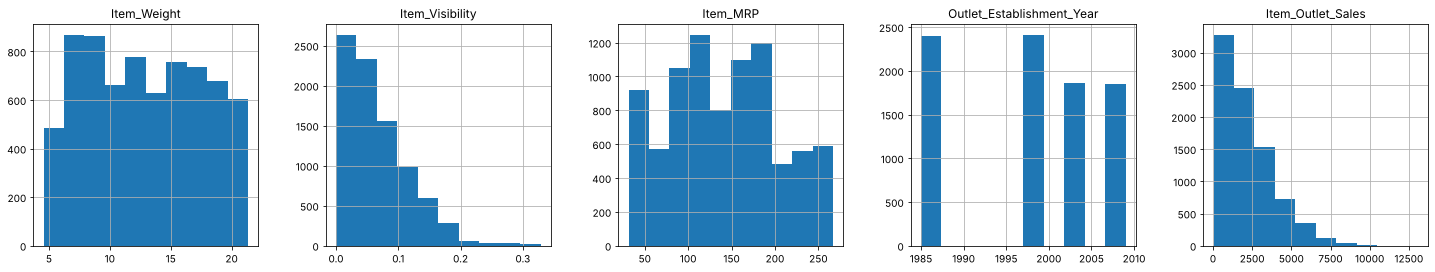

In [12]:
sales_df.hist(figsize=(25,4), layout=(1,5))
plt.show()

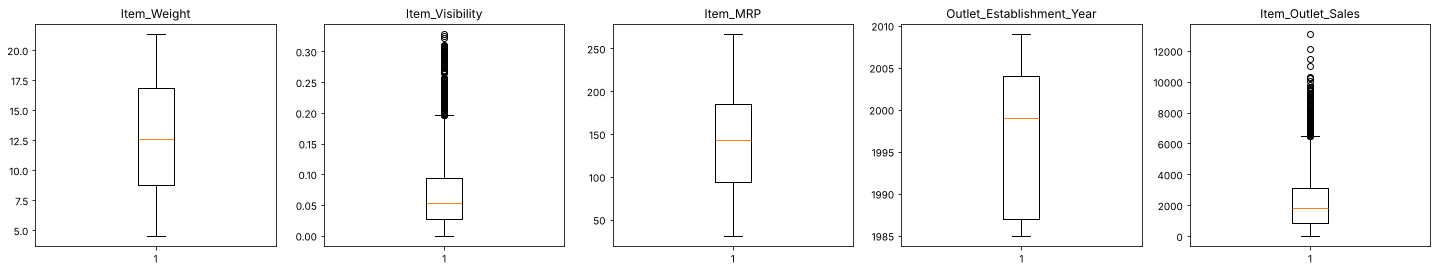

In [13]:
fig, axes = plt.subplots(1,5, figsize=(25,4))
axes = axes.ravel()
for col, ax in zip(sales_df[num_cols], axes):
  ax.boxplot(sales_df[col].dropna())
  ax.set_title(col)
plt.show()

**Análisis univariado de variables categóricas**

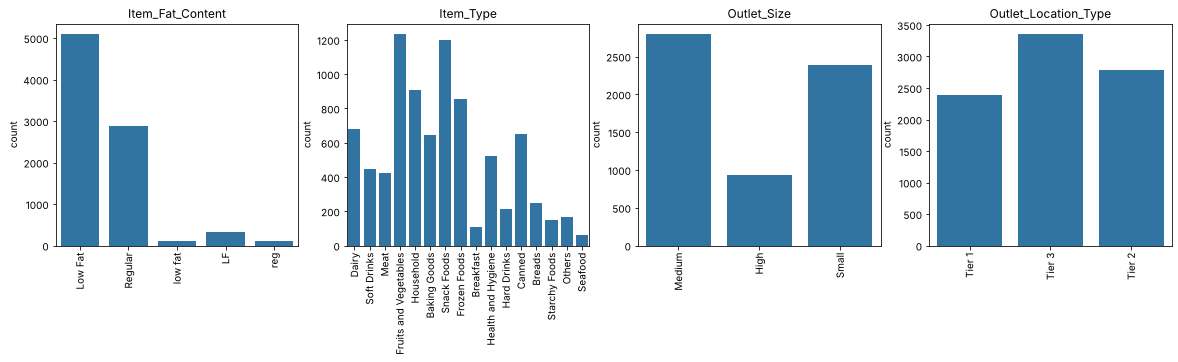

In [14]:
fig, axes = plt.subplots(1,4, figsize=(20,4))
axes = axes.ravel()
for col, ax in zip(sales_df[cat_cols], axes):
  sns.countplot(x=sales_df[col], ax=ax)
  ax.set(title=f'{col}', xlabel=None)
  ax.tick_params(axis='x',rotation=90)

En `Ite_Fat_Content` hay categorías expresadas de diferente forma:
*   Low Fat = low fat = LF
*   Regular = reg

Se unifica, para sólo dejar dos valores: Low Fat y Regular



In [15]:
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Low Fat' if x == 'low fat' or x == 'LF' else x)
sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].apply(lambda x: 'Regular' if x == 'reg' else x)

<Axes: xlabel='Item_Fat_Content', ylabel='count'>

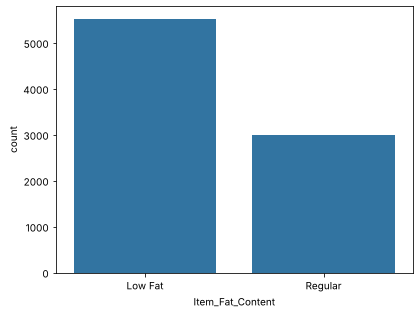

In [16]:
sns.countplot(x=sales_df['Item_Fat_Content'])

**Análisis bivariado**

<Axes: >

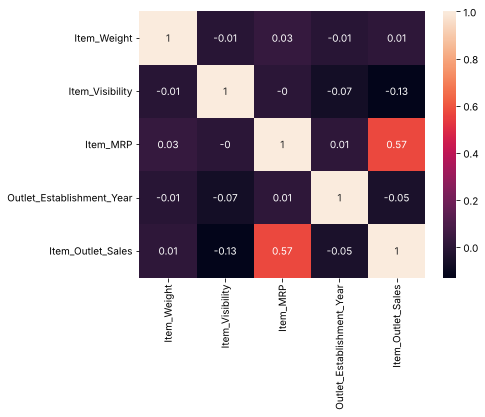

In [17]:
sns.heatmap(round(sales_df.corr(numeric_only=True),2), annot = True)

Del gráfico anterior, parece que solo la variable independiente `Item_MRP` tiene una relación lineal moderada con la variable dependiente `Item_Outlet_Sales`. Se verifica con diagramas de dispersión.

<Axes: xlabel='Item_MRP', ylabel='Item_Outlet_Sales'>

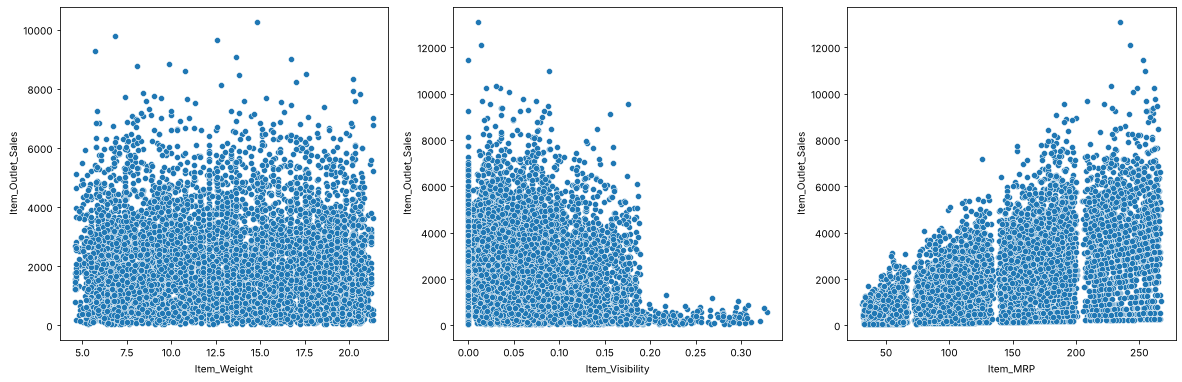

In [18]:
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='Item_Weight', y='Item_Outlet_Sales', data=sales_df, ax=axes[0])
sns.scatterplot(x='Item_Visibility', y='Item_Outlet_Sales', data=sales_df, ax=axes[1])
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', data=sales_df, ax=axes[2])

Se crea una nueva característica `Outlet_Age` que indica la antigüedad del outlet.

In [19]:
from datetime import date #permite trabajar con fechas
#date.today().year, obtiene el año actual
#sales_df['Outlet_Establishment_year'], columna que tinee el año que se fundo cada tienda
sales_df['Outlet_Age'] = date.today().year - sales_df['Outlet_Establishment_Year'] #calcula la edad de cada tienda en años

sales_df.drop('Outlet_Establishment_Year', axis = 1, inplace=True) #elimina la columan original
    #se elimina porque ya no es necesaria, ya que fue transformada auna forma mas util para el modelo
    #ayuda a reducir la dimensionalidad del dataset y evita redundancia

    #axis=1, indica que se elimnara una COLUMNA (en lugar de una fila)
    #inplace=true, guarda cambios directamente en el df

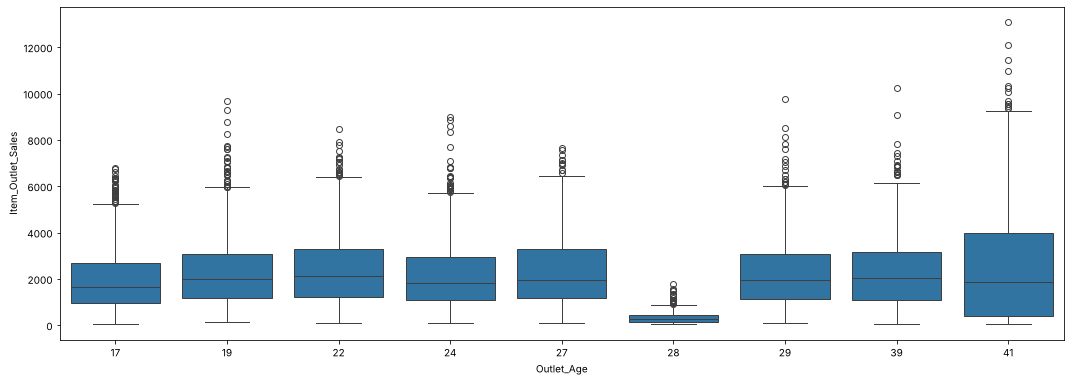

In [20]:
fig = plt.figure(figsize = (18, 6))
sns.boxplot(x = 'Outlet_Age', y = 'Item_Outlet_Sales', data = sales_df);

**INCIO MODELO MACHINE LEARNING**

INGENIERIA DE CARACTERISTICAS

Se especifican cuales seran las variables de entrada 'X' (Caracteristica) y cual sera la varible predictora 'y' (variable salida o
tambien Objetivo)

In [21]:
# Se separan las variables del dataframe: en X quedan los predictores y en y la variable de respuesta o salida (Item_Outlet_Sales).
X = sales_df.drop('Item_Outlet_Sales', axis = 1) #variables de entrada - Caracteristica
y = sales_df['Item_Outlet_Sales'] #variable salida -variable predictora - Objetivo

**PARTICION DEL CONJUNTO DE DATOS**

In [22]:
# Se divide el conjunto en entrenamiento y prueba (80:20)
#80% conjunto de entrenamiento(train)
#20% para el conjunto de prueba (test)

from sklearn.model_selection import train_test_split

Xtrain, Xtest, ytrain, ytest = train_test_split(X,#variable entrada
                                                y,#variable salida o predictora
                                                train_size=0.8, # tama;o conjunto entrenamiento
                                                random_state=1) #para mantener mismo conjunto de datos

PROCESAMIENTO

**CANALIZACION (PIPELINE)**

In [23]:
# Como se aplicará más de un transformador y de manera diferenciada (numéricas y categóricas reciben diferentes tratamientos),
# hay que crear pipelines (aquí se nombraron como: num_pipeline y cat_pipeline) para transformar las columnas

# Si sólo fuera un transformador en cada tipo de variable, no sería necesario crer num_pipeline ni cat_pipeline.
# El transformador único podría ir directamente en el ColumnTransformer que aparece abajo
#PARA VARIABLES NUMERICAS
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), MinMaxScaler())
      #Rellena valores faltantes con la media
      #aplica escalado MinMaxScaler, para que todas los valores numericos esten en el rango [0,1]


#PARA VARIABLES CATEGORICAS
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
      #Rellena valores faltantes con la categoria mas frecuente
      #Convierte categorias en columnas binarias (0,1) con OneHOt

        #parametros de OneHot
          #drop='first', evita la trampa multicolinealidad, eliminando la primer categoria
                #Multicolaniedad- se refiere cuando se da la situacion que dos o mas columnas en un modelo de regresion estan altamente correlacionadas entre si.
                    #es decir, que el modelo no distinga cual es 'y' (variable predictora)
                    #esta alta correlacion puede generar problemas de ajuste del modelo.
                    #si nos variables (columnas), son muy similares, el modelo no puede distinguir cual de ellas tiene mayor influencia en X (variables de entrada)

          #handle_unknown='ignore', ignora nuevas categorias que no se vieron durante el entrenamiento (evita errores de produccion)
          #sparse_output=False, devuelve matriz densa, util si vas a convertir el resultado a un DF)

#UNE PREPROCESAMIENTOS
preprocessing = ColumnTransformer([
    ('num', num_pipeline, make_column_selector(dtype_include=np.number)), #detecta TODAS columnas numericas                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                     , make_column_selector(dtype_include=np.number)),
    ('cat', cat_pipeline, make_column_selector(dtype_include=object))])   #detecta TODAS columnas categoricas

In [24]:
# Esto no es necesario, pero lo incluyo para que se visualicen los cambios que produce el pipeline "preprocessing" creado anteriormente
# Nótese que Xtrain queda con 27 columnas después del procesamiento, es decir, se utilizarán 27 predictores en el modelo (4 numéricos y 23 categóricos)

Xtrain_prepared = preprocessing.fit_transform(Xtrain)
Xtrain_prepared_df = pd.DataFrame(Xtrain_prepared, columns=preprocessing.get_feature_names_out(), index=Xtrain.index)
Xtrain_prepared_df

,num__Item_Weight,num__Item_Visibility,num__Item_MRP,num__Outlet_Age,cat__Item_Fat_Content_Regular,cat__Item_Type_Breads,cat__Item_Type_Breakfast,cat__Item_Type_Canned,cat__Item_Type_Dairy,cat__Item_Type_Frozen Foods,cat__Item_Type_Fruits and Vegetables,cat__Item_Type_Hard Drinks,cat__Item_Type_Health and Hygiene,cat__Item_Type_Household,cat__Item_Type_Meat,cat__Item_Type_Others,cat__Item_Type_Seafood,cat__Item_Type_Snack Foods,cat__Item_Type_Soft Drinks,cat__Item_Type_Starchy Foods,cat__Outlet_Size_Medium,cat__Outlet_Size_Small,cat__Outlet_Location_Type_Tier 2,cat__Outlet_Location_Type_Tier 3,cat__Outlet_Type_Supermarket Type1,cat__Outlet_Type_Supermarket Type2,cat__Outlet_Type_Supermarket Type3
1945,0.821375,0.272069,0.681925,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1720,0.761834,0.511783,0.615374,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
1954,0.330158,0.164095,0.824788,0.083333,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1919,0.374814,0.496066,0.312702,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
2461,0.155701,0.181846,0.423207,0.208333,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2895,0.479012,0.844906,0.531008,1.000000,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
7813,0.479012,0.542624,0.100619,1.000000,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
905,0.791605,0.200402,0.500067,0.500000,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
5192,0.300387,0.151094,0.054833,0.458333,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0


**APLICA PREPROCESAMIENTO ANTERIOR PARA EL**

**ENTRENAMIENTO DEL MODELO REGRESION LINEAL**

In [25]:
# Se crea el pipeline para la predicción, que incluye el de procesamiento creado anteriormente y la regresión lineal

#CREA PIPELINE
lr_model = make_pipeline(preprocessing, LinearRegression())
    #PREPROCESING, procesa los datos (relleno de nulos, escalado (minMaxScaler), codificacion (OneHOtEnconder))
    #LinearRegresion, aplica modelo de regresion lineal a los datos ya entrenados

#ENTRENA Y AJUSTA TODO EL PIPELINE CON LOS DATOS DE ENTRENAMIENTO
lr_model.fit(Xtrain, ytrain)
    #primero transforma Xtrain con el preprocesador
    #luego entrena el modelo de LinearRegresion() con las variables transformadas y la variable objetivo ytrain

#APLICA PIPELINE A LOS DATOS DE PRUEBA
predictions = lr_model.predict(Xtest)
  #primero transforma con el mismo preprocesador (usando los parametros aprendidos en fit)
  #despues realiza predicciones con el modelo entrenado

#CALCULA VALOR RMSE ENTRE VALORES REALES (ytest) y los valores predichos por el modelo (Predictions)
print('The Root Mean Square Error (RMSE) is:', np.sqrt(mean_squared_error(ytest, predictions)))
#RMSE nos dice en promedio cuanto se equivoco tu modelo al predecir, en las mismas unidades que la variable objetivo

#esta metrica indica que proporcion de la variacion de la variable dependiente (ytest) es explicada por el modelo
print('The R square (R2) is:', r2_score(ytest, predictions))
#r2= 1, prediccion perfecta
#r2= 0, el modelo no explica mejor que un promedio
#r2<0, el modelo es peor

The Root Mean Square Error (RMSE) is: 1144.3827848578724
The R square (R2) is: 0.5582080574611583


RMSE = 1144.38, significa que el modelo se equivoca por unas 1144.38 unidades.

r2 =0.558, significa que elmodelo explcia el 55.8% de la variabilidad de los datos, el 42% restante, no lo puede explicar (puede deberse al ruido, datos faltantes, variables importantes no incluidas), o hacer uso de otro tipo de transformaciones de variables.

El resultado obtenido por el modelo de regresion lineal no es excelente, debido a que esta haciendo predicciones con un error moderado y explica poco mas de la mitad del comportamiento de la variable objetivo

Lo que seguiría es hacer más transformaciones para mejorar el resultado. Por ejemplo:

* Aplicar una transformación (log, box-cox,...) para hacer que la distribución de `Item_Visibility` tenga una forma más normal, porque está sesgada.

* Usar StandarScaler o RobustScaler en lugar de MinMax.
* Aplicar OrdinalEncoder a algunas categóricas, en lugar de OneHotEncoder.

In [26]:
# Se puede tener acceso a los pasos ejecutados en el pipeline
lr_model.named_steps

{'columntransformer': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('minmaxscaler',
                                                  MinMaxScaler())]),
                                 <sklearn.compose._column_transformer.make_column_selector object at 0x7fc4c3c54830>),
                                ('cat',
                                 Pipeline(steps=[('simpleimputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehotencoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
          

In [27]:
# Una vez ubicado en un paso, por ejemplo en la regresión lineal ('linearregression'), se puede tener acceso a sus atributos
# Para mostrar la intercepción o beta_0
lr_model.named_steps['linearregression'].intercept_

np.float64(274.6134468529351)

In [28]:
# Para mostrar los coeficientes: beta_1, beta_2, ... beta_n
# En este caso se obtienen 27 coeficientes, uno por predictor
lr_model.named_steps['linearregression'].coef_

array([  28.62355263,  -97.09612341, 3678.93686232, -883.7484864 ,
         36.0930557 ,    9.09628309,  -15.7209235 ,   34.68740649,
       -100.45813405,  -39.04913619,   38.07938416,  -23.89284596,
         10.9988591 ,  -62.51983653,  -33.90791199,  -36.06410826,
        283.24072408,   15.10818476,  -74.74109576,   35.98874243,
       -839.68268244, -746.65228891, -202.1755319 , -395.31896407,
       1509.68985198, 1243.4315047 , 3872.29804368])

In [29]:
# Para mostrar los transformadores ejecutados
lr_model.named_steps['columntransformer']

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [30]:
# Para tener acceso a un transformador en particular
lr_model.named_steps['columntransformer'].named_transformers_['num']

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('minmaxscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['Item_Weight','Item_Visibility','Item_MRP','Outlet_Age']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,

In [31]:
# Para tener acceso a los atributos de un transformador en particular
# Como sólo se tienen 4 predictores numéricos, se calcula el mínimo de cada uno
lr_model.named_steps['columntransformer'].named_transformers_['num'].named_steps['minmaxscaler'].min_

array([-0.27121167,  0.        , -0.13281075, -0.70833333])

---
# **MODELO MEJORADO: objetivo R² ≥ 0.70**

El modelo base explica alrededor del 56% de la variabilidad. Para mejorarlo se aplican las transformaciones sugeridas arriba:

1. **Transformación logarítmica de la variable objetivo** (`Item_Outlet_Sales`). Las ventas tienen un sesgo positivo muy marcado (muchas ventas pequeñas y pocas muy grandes). Además, las ventas se comportan de forma *multiplicativa*: ventas ≈ precio (`Item_MRP`) × unidades vendidas, y las unidades dependen del tipo de tienda. Al aplicar logaritmo, esa relación multiplicativa se vuelve **lineal**, que es justo lo que la regresión lineal puede modelar:
   log(ventas) = log(precio) + efecto de la tienda + ...
2. **Logaritmo de `Item_MRP`** para que quede en la misma escala que el objetivo.
3. **Raíz cuadrada de `Item_Visibility`** porque está sesgada (y tiene ceros, por eso no se usa log).
4. **StandardScaler** en lugar de MinMaxScaler para las variables numéricas.

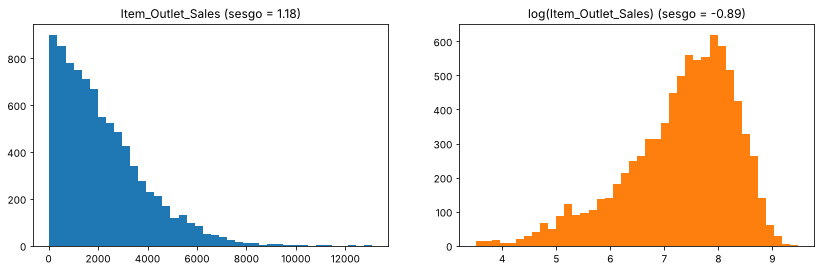

In [32]:
# Distribución de la variable objetivo antes y después de aplicar logaritmo
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(sales_df['Item_Outlet_Sales'], bins=40)
axes[0].set_title(f"Item_Outlet_Sales (sesgo = {sales_df['Item_Outlet_Sales'].skew():.2f})")
axes[1].hist(np.log(sales_df['Item_Outlet_Sales']), bins=40, color='tab:orange')
axes[1].set_title(f"log(Item_Outlet_Sales) (sesgo = {np.log(sales_df['Item_Outlet_Sales']).skew():.2f})")
plt.show()

In [33]:
from sklearn.preprocessing import StandardScaler, FunctionTransformer

# Transformación de la variable objetivo con logaritmo natural
ytrain_log = np.log(ytrain)
ytest_log = np.log(ytest)

# Pipeline para Item_MRP: imputar -> logaritmo -> estandarizar
mrp_pipeline = make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log), StandardScaler())

# Pipeline para Item_Visibility: imputar -> raíz cuadrada (tiene ceros) -> estandarizar
vis_pipeline = make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.sqrt), StandardScaler())

# Resto de numéricas (Item_Weight, Outlet_Age): imputar -> estandarizar
num_pipeline2 = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())

# Categóricas: igual que en el modelo base
cat_pipeline2 = make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))

preprocessing2 = ColumnTransformer([
    ('mrp', mrp_pipeline, ['Item_MRP']),
    ('vis', vis_pipeline, ['Item_Visibility']),
    ('num', num_pipeline2, ['Item_Weight', 'Outlet_Age']),
    ('cat', cat_pipeline2, make_column_selector(dtype_include=object))])

In [34]:
# Se crea y entrena el pipeline del modelo mejorado
lr_model2 = make_pipeline(preprocessing2, LinearRegression())
lr_model2.fit(Xtrain, ytrain_log)          # se entrena con log(ventas)

predictions_log = lr_model2.predict(Xtest) # predicciones en escala logarítmica

print('R2 entrenamiento (escala log):', round(r2_score(ytrain_log, lr_model2.predict(Xtrain)), 4))
print('R2 prueba (escala log)       :', round(r2_score(ytest_log, predictions_log), 4))
print('RMSE prueba (escala log)     :', round(np.sqrt(mean_squared_error(ytest_log, predictions_log)), 4))

R2 entrenamiento (escala log): 0.7393
R2 prueba (escala log)       : 0.7497
RMSE prueba (escala log)     : 0.5262


In [35]:
# Para interpretar el error en las unidades originales, se regresa la predicción a la escala original con exp()
predictions2 = np.exp(predictions_log)
print('RMSE en unidades originales:', round(np.sqrt(mean_squared_error(ytest, predictions2)), 2))
print('Error porcentual absoluto mediano:', round(np.median(np.abs(ytest - predictions2) / ytest) * 100, 1), '%')

RMSE en unidades originales: 1118.12
Error porcentual absoluto mediano: 32.5 %


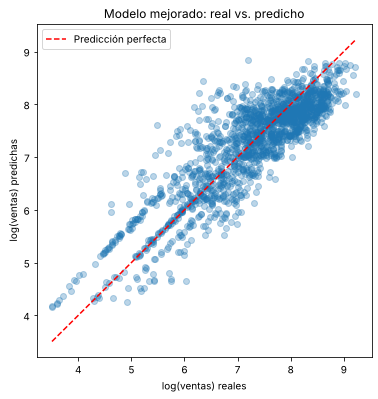

In [36]:
# Comparación gráfica: valores reales vs. predichos (escala log)
plt.figure(figsize=(6, 6))
plt.scatter(ytest_log, predictions_log, alpha=0.3)
lims = [ytest_log.min(), ytest_log.max()]
plt.plot(lims, lims, 'r--', label='Predicción perfecta')
plt.xlabel('log(ventas) reales')
plt.ylabel('log(ventas) predichas')
plt.title('Modelo mejorado: real vs. predicho')
plt.legend()
plt.show()

In [37]:
# Tabla comparativa de ambos modelos
pd.DataFrame({
    'Modelo': ['Base (MinMax, y original)', 'Mejorado (log + StandardScaler)'],
    'R2 prueba': [round(r2_score(ytest, predictions), 4), round(r2_score(ytest_log, predictions_log), 4)]
})

,Modelo,R2 prueba
0,"Base (MinMax, y original)",0.5582
1,Mejorado (log + StandardScaler),0.7497


**CONCLUSIÓN DEL MODELO MEJORADO**

* Con la transformación logarítmica de la variable objetivo el modelo alcanza un **R² ≈ 0.75 en el conjunto de prueba**, es decir, explica cerca del **75% de la variabilidad** de las ventas (en escala logarítmica), superando el 70% requerido y el 56% del modelo base.
* El R² de entrenamiento y el de prueba son prácticamente iguales, por lo que **no hay sobreajuste**: el modelo generaliza bien a datos nuevos.
* La mejora se explica porque las ventas dependen del precio y del tipo de tienda de forma multiplicativa; el logaritmo convierte esa relación en una suma, que la regresión lineal sí puede capturar. Además reduce el sesgo de la distribución y el peso de las ventas extremas.
* Las variables más importantes siguen siendo `Item_MRP` (precio) y `Outlet_Type` (las tiendas *Grocery Store* venden mucho menos que los supermercados).
* El error en unidades originales también mejoró: RMSE de 1118 contra 1144 del modelo base.
* Nota: al regresar las predicciones a pesos con `exp()`, el R² en escala original es cercano a 0.58; la variabilidad restante corresponde a factores que no están en los datos (promociones, temporada, ubicación exacta, etc.).